In [1]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.preprocessing import MinMaxScaler, OrdinalEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)

In [2]:
uploaded = files.upload()

file_name = next(iter(uploaded.keys()))

if file_name.lower().endswith(".zip"):
    with zipfile.ZipFile(file_name, "r") as z:
        z.extractall("/content/dataset")
    csv_files = []
    for root, dirs, filenames in os.walk("/content/dataset"):
        for f in filenames:
            if f.lower().endswith(".csv"):
                csv_files.append(os.path.join(root, f))

    print("CSV files found:", csv_files)
    if not csv_files:
        raise ValueError("No CSV file found inside the ZIP.")
    csv_path = csv_files[0]

elif file_name.lower().endswith(".csv"):
    csv_path = file_name

else:
    raise ValueError("Please upload a CSV file or a ZIP containing CSV files.")

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Original shape:", df.shape)
display(df.head())

Saving synthetic_traffic_benchmark_200k.csv to synthetic_traffic_benchmark_200k.csv
Dataset loaded successfully!
Original shape: (200000, 29)


,Record_ID,Timestamp,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,...,Vehicle_Age_yrs,Recorded_Speed_kmh,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min
0,REC_0000000,2024-03-14 17:35:06.841829282,2024-03-14,17,3,Thursday,Evening Peak,0,Urban,Interstate,...,7.2,49.0,6.2,0,NaN,0,No Accident,NaN,0.0,0.0
1,REC_0000001,2023-05-25 08:10:56.398060108,2023-05-25,8,5,Thursday,Morning Peak,0,Suburban,Interstate,...,9.4,70.1,15.0,0,NaN,0,No Accident,NaN,0.0,0.0
2,REC_0000002,2023-11-07 08:25:17.721608262,2023-11-07,8,11,Tuesday,Morning Peak,0,Suburban,Interstate,...,2.9,71.9,14.6,0,NaN,0,No Accident,NaN,0.0,0.0
3,REC_0000003,2024-07-24 09:30:00.947374674,2024-07-24,9,7,Wednesday,Morning Peak,0,Suburban,Collector,...,4.4,58.7,13.2,0,NaN,0,No Accident,NaN,0.0,0.0
4,REC_0000004,2024-04-03 09:34:07.316651267,2024-04-03,9,4,Wednesday,Morning Peak,0,Urban,Local,...,1.8,25.4,7.8,0,NaN,0,No Accident,NaN,0.0,0.0


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()

Column names:
['Record_ID', 'Timestamp', 'Date', 'Hour', 'Month', 'Day_of_Week', 'Time_of_Day', 'Is_Holiday', 'Area_Type', 'Road_Type', 'Intersection_Type', 'Speed_Limit_kmh', 'Weather', 'Road_Condition', 'Visibility_m', 'Congestion_Index', 'Vehicle_Type', 'Driver_Age', 'Driver_Experience_yrs', 'Vehicle_Age_yrs', 'Recorded_Speed_kmh', 'Baseline_Expected_Response_Time_min', 'Accident_Occurred', 'Collision_Type', 'Vehicles_Involved', 'Accident_Severity', 'Dispatch_Priority', 'Actual_Response_Time_min', 'Road_Closure_Duration_min']

Data types:
Record_ID                               object
Timestamp                               object
Date                                    object
Hour                                     int64
Month                                    int64
Day_of_Week                             object
Time_of_Day                             object
Is_Holiday                               int64
Area_Type                               object
Road_Type                    

In [4]:
# Change these two values if automatic detection is incorrect.
TIME_COL = None
TARGET_COL = None

# Example manual settings:
# TIME_COL = "timestamp"
# TARGET_COL = "traffic_congestion"

def find_column(columns, candidates):
    lookup = {str(c).lower().strip(): c for c in columns}

    for name in candidates:
        if name in lookup:
            return lookup[name]

    for c in columns:
        name = str(c).lower().strip()
        if any(term in name for term in candidates):
            return c

    return None

if TIME_COL is None:
    TIME_COL = find_column(
        df.columns,
        ["timestamp", "datetime", "date_time", "date time",
         "event_time", "recorded_at", "time", "date"]
    )

if TARGET_COL is None:
    TARGET_COL = find_column(
        df.columns,
        ["traffic_congestion", "congestion_level",
         "congestion", "traffic_density", "congestion_index",
         "traffic_flow", "traffic_speed", "traffic_volume"]
    )

print("Detected time column:", TIME_COL)
print("Detected target column:", TARGET_COL)

if TIME_COL is None:
    raise ValueError(
        "No timestamp column detected. Check the column names above "
        "and set TIME_COL manually. A meaningful time-series forecast "
        "requires a time column."
    )

if TARGET_COL is None:
    raise ValueError(
        "No suitable traffic target detected. Check the columns above "
        "and set TARGET_COL to the actual traffic congestion measure."
    )

if TIME_COL == TARGET_COL:
    raise ValueError("The time and target columns must be different.")

Detected time column: Timestamp
Detected target column: Congestion_Index


In [5]:
df = df.head(10000).copy()

df[TIME_COL] = pd.to_datetime(
    df[TIME_COL], errors="coerce"
)

df = df.dropna(subset=[TIME_COL])
df = df.sort_values(TIME_COL).reset_index(drop=True)

print("Records selected:", len(df))
print("Time range:", df[TIME_COL].min(), "to", df[TIME_COL].max())

display(df.head())

Records selected: 10000
Time range: 2022-01-01 14:05:51.868209219 to 2025-12-31 19:07:18.273868984


,Record_ID,Timestamp,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,...,Vehicle_Age_yrs,Recorded_Speed_kmh,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min
0,REC_0003324,2022-01-01 14:05:51.868209219,2022-01-01,14,1,Saturday,Midday,0,Suburban,Local,...,5.3,18.9,9.1,0,NaN,0,No Accident,NaN,0.0,0.0
1,REC_0006753,2022-01-01 15:25:44.949451008,2022-01-01,15,1,Saturday,Midday,0,Suburban,Arterial,...,15.7,61.8,7.9,0,NaN,0,No Accident,NaN,0.0,0.0
2,REC_0009613,2022-01-01 17:38:29.839683298,2022-01-01,17,1,Saturday,Evening Peak,0,Suburban,Arterial,...,5.5,40.2,8.7,0,NaN,0,No Accident,NaN,0.0,0.0
3,REC_0005453,2022-01-01 19:26:09.902414225,2022-01-01,19,1,Saturday,Evening Peak,0,Rural,Collector,...,3.1,56.2,22.4,0,NaN,0,No Accident,NaN,0.0,0.0
4,REC_0007123,2022-01-01 22:48:59.895966278,2022-01-01,22,1,Saturday,Night,0,Urban,Local,...,10.7,14.4,7.9,0,NaN,0,No Accident,NaN,0.0,0.0


In [6]:
# Convert the target into a numeric value when possible.
target = df[TARGET_COL]

if pd.api.types.is_numeric_dtype(target):
    df[TARGET_COL] = pd.to_numeric(target, errors="coerce")
else:
    text_target = target.astype("string").str.strip().str.lower()

    # Handle common ordered congestion labels.
    congestion_map = {
        "low": 0, "low congestion": 0,
        "medium": 1, "moderate": 1, "medium congestion": 1,
        "high": 2, "high congestion": 2,
        "severe": 3, "very high": 3, "very high congestion": 3
    }

    mapped = text_target.map(congestion_map)

    if mapped.notna().sum() > 0:
        df[TARGET_COL] = mapped
    else:
        # General categorical target: assign numeric class codes.
        # These codes do not necessarily represent congestion severity.
        df[TARGET_COL] = pd.Categorical(text_target).codes
        df.loc[df[TARGET_COL] == -1, TARGET_COL] = np.nan

df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors="coerce")

# Remove rows where the target is unavailable.
df = df.dropna(subset=[TARGET_COL]).copy()

# Add useful time features.
df["hour_of_day"] = df[TIME_COL].dt.hour
df["day_of_week"] = df[TIME_COL].dt.dayofweek

# Exclude original timestamp from the model input.
feature_df = df.drop(columns=[TIME_COL]).copy()

# Convert boolean columns to integers.
for col in feature_df.select_dtypes(include=["bool"]).columns:
    feature_df[col] = feature_df[col].astype(int)

# Convert numeric-looking text columns when most values are numeric.
for col in feature_df.select_dtypes(include=["object", "string"]).columns:
    converted = pd.to_numeric(feature_df[col], errors="coerce")
    if converted.notna().mean() >= 0.8:
        feature_df[col] = converted

numeric_cols = feature_df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [c for c in feature_df.columns if c not in numeric_cols]

# Fill numerical missing values.
for col in numeric_cols:
    feature_df[col] = feature_df[col].replace([np.inf, -np.inf], np.nan)
    feature_df[col] = feature_df[col].fillna(feature_df[col].median())

# Fill and encode categorical columns.
for col in categorical_cols:
    feature_df[col] = feature_df[col].fillna("Unknown").astype(str)

    encoder = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )
    feature_df[[col]] = encoder.fit_transform(feature_df[[col]])

feature_df = feature_df.replace([np.inf, -np.inf], np.nan)

# Final cleanup.
feature_df = feature_df.dropna(subset=[TARGET_COL]).reset_index(drop=True)

print("Processed data shape:", feature_df.shape)
print("Remaining missing values:", int(feature_df.isnull().sum().sum()))
print("Numerical features:", numeric_cols)
print("Encoded categorical features:", categorical_cols)

display(feature_df.head())

Processed data shape: (10000, 30)
Remaining missing values: 0
Numerical features: ['Hour', 'Month', 'Is_Holiday', 'Speed_Limit_kmh', 'Visibility_m', 'Congestion_Index', 'Driver_Age', 'Driver_Experience_yrs', 'Vehicle_Age_yrs', 'Recorded_Speed_kmh', 'Baseline_Expected_Response_Time_min', 'Accident_Occurred', 'Vehicles_Involved', 'Actual_Response_Time_min', 'Road_Closure_Duration_min', 'hour_of_day', 'day_of_week']
Encoded categorical features: ['Record_ID', 'Date', 'Day_of_Week', 'Time_of_Day', 'Area_Type', 'Road_Type', 'Intersection_Type', 'Weather', 'Road_Condition', 'Vehicle_Type', 'Collision_Type', 'Accident_Severity', 'Dispatch_Priority']


,Record_ID,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,Intersection_Type,...,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min,hour_of_day,day_of_week
0,3324.0,0.0,14,1,2.0,1.0,0,1.0,3.0,2.0,...,9.1,0,4.0,0,3.0,3.0,0.0,0.0,14,5
1,6753.0,0.0,15,1,2.0,1.0,0,1.0,0.0,0.0,...,7.9,0,4.0,0,3.0,3.0,0.0,0.0,15,5
2,9613.0,0.0,17,1,2.0,0.0,0,1.0,0.0,0.0,...,8.7,0,4.0,0,3.0,3.0,0.0,0.0,17,5
3,5453.0,0.0,19,1,2.0,0.0,0,0.0,1.0,0.0,...,22.4,0,4.0,0,3.0,3.0,0.0,0.0,19,5
4,7123.0,0.0,22,1,2.0,3.0,0,2.0,3.0,2.0,...,7.9,0,4.0,0,3.0,3.0,0.0,0.0,22,5


Hourly dataset shape: (8225, 31)


,timestamp,Record_ID,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,...,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min,hour_of_day,day_of_week
0,2022-01-01 14:00:00,3324.0,0.0,14.0,1.0,2.0,1.0,0.0,1.0,3.0,...,9.10,0.0,4.0,0.0,3.0,3.0,0.0,0.0,14.0,5.0
1,2022-01-01 15:00:00,6753.0,0.0,15.0,1.0,2.0,1.0,0.0,1.0,0.0,...,7.90,0.0,4.0,0.0,3.0,3.0,0.0,0.0,15.0,5.0
2,2022-01-01 17:00:00,9613.0,0.0,17.0,1.0,2.0,0.0,0.0,1.0,0.0,...,8.70,0.0,4.0,0.0,3.0,3.0,0.0,0.0,17.0,5.0
3,2022-01-01 19:00:00,5453.0,0.0,19.0,1.0,2.0,0.0,0.0,0.0,1.0,...,22.40,0.0,4.0,0.0,3.0,3.0,0.0,0.0,19.0,5.0
4,2022-01-01 22:00:00,7123.0,0.0,22.0,1.0,2.0,3.0,0.0,2.0,3.0,...,7.90,0.0,4.0,0.0,3.0,3.0,0.0,0.0,22.0,5.0
5,2022-01-02 07:00:00,8832.0,1.0,7.0,1.0,3.0,2.0,0.0,0.0,3.0,...,20.00,0.0,4.0,0.0,3.0,3.0,0.0,0.0,7.0,6.0
6,2022-01-02 11:00:00,9723.0,1.0,11.0,1.0,3.0,1.0,0.0,2.0,3.0,...,8.70,0.0,4.0,0.0,3.0,3.0,0.0,0.0,11.0,6.0
7,2022-01-02 15:00:00,5610.5,1.0,15.0,1.0,3.0,1.0,0.0,1.5,2.5,...,10.95,0.0,4.0,0.0,3.0,3.0,0.0,0.0,15.0,6.0
8,2022-01-03 06:00:00,2836.0,2.0,6.0,1.0,1.0,2.0,0.0,1.0,3.0,...,9.60,0.0,4.0,0.0,3.0,3.0,0.0,0.0,6.0,0.0
9,2022-01-03 09:00:00,3780.0,2.0,9.0,1.0,1.0,2.0,0.0,2.0,1.0,...,8.30,0.0,4.0,0.0,3.0,3.0,0.0,0.0,9.0,0.0


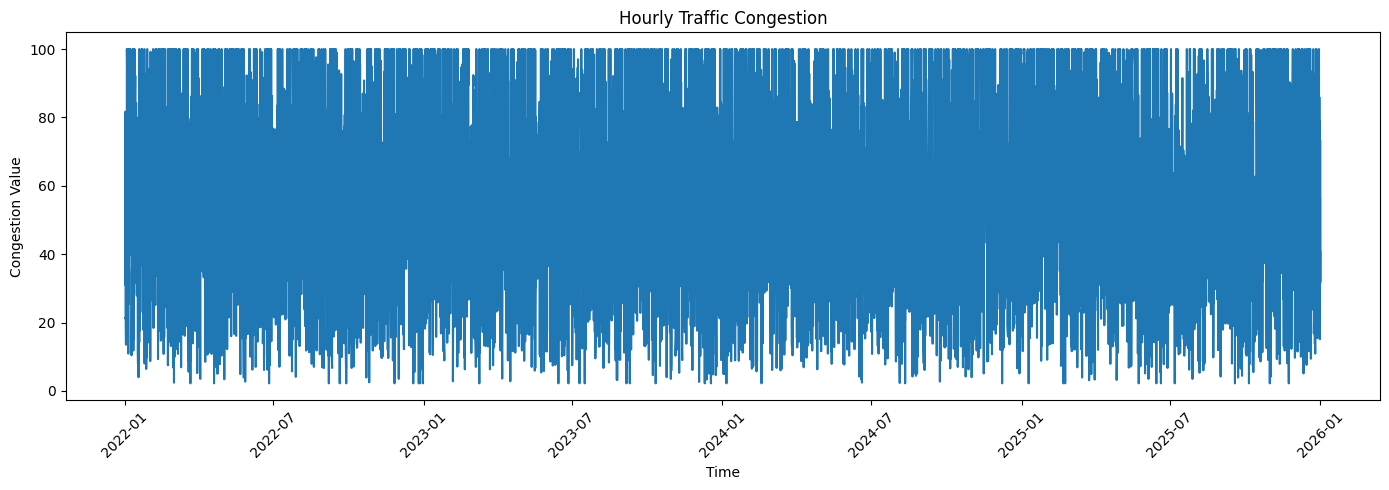

In [7]:
# Recover timestamps aligned with the cleaned feature rows.
time_series = df.dropna(subset=[TARGET_COL])[TIME_COL].reset_index(drop=True)

if len(time_series) != len(feature_df):
    raise ValueError(
        "Timestamp and feature rows do not match. "
        "Re-run the preprocessing after resetting the dataframe index."
    )

hourly = feature_df.copy()
hourly["timestamp"] = time_series.values

hourly = hourly.set_index("timestamp").sort_index()

# Group by clock hour.
hourly = hourly.resample("h").mean(numeric_only=True)

# Remove hours with no observations.
hourly = hourly.dropna(subset=[TARGET_COL]).reset_index()

print("Hourly dataset shape:", hourly.shape)
display(hourly.head(10))

plt.figure(figsize=(14, 5))
plt.plot(hourly["timestamp"], hourly[TARGET_COL])
plt.title("Hourly Traffic Congestion")
plt.xlabel("Time")
plt.ylabel("Congestion Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
LOOKBACK = 24  # Use the previous 24 hourly observations.

if len(hourly) <= LOOKBACK + 5:
    raise ValueError(
        "Not enough hourly observations for sequence forecasting. "
        "Check the timestamp range and available records."
    )

feature_cols = [
    c for c in hourly.columns
    if c not in ["timestamp"]
]

X = hourly[feature_cols].to_numpy(dtype=np.float32)
y = hourly[TARGET_COL].to_numpy(dtype=np.float32)

split_index = int(len(hourly) * 0.8)

# Fit scalers only on training data to reduce data leakage.
x_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()

x_scaler.fit(X[:split_index])
y_scaler.fit(y[:split_index].reshape(-1, 1))

X_scaled = x_scaler.transform(X)
y_scaled = y_scaler.transform(y.reshape(-1, 1)).ravel()

print("Total hourly observations:", len(hourly))
print("Training observations:", split_index)
print("Testing observations:", len(hourly) - split_index)
print("Input features:", len(feature_cols))

Total hourly observations: 8225
Training observations: 6580
Testing observations: 1645
Input features: 30


In [9]:
def create_sequences(X_data, y_data, lookback, start_index, end_index):
    X_seq, y_seq = [], []

    for i in range(max(lookback, start_index), end_index):
        X_seq.append(X_data[i-lookback:i])
        y_seq.append(y_data[i])

    return np.array(X_seq), np.array(y_seq)

X_train, y_train = create_sequences(
    X_scaled, y_scaled, LOOKBACK, 0, split_index
)

X_test, y_test = create_sequences(
    X_scaled, y_scaled, LOOKBACK, split_index, len(hourly)
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

if len(X_train) == 0 or len(X_test) == 0:
    raise ValueError("Not enough sequences. Check your dataset size and timestamps.")

X_train shape: (6556, 24, 30)
y_train shape: (6556,)
X_test shape: (1645, 24, 30)
y_test shape: (1645,)


In [10]:
model = Sequential([
    LSTM(64, return_sequences=True,
         input_shape=(LOOKBACK, X_train.shape[2])),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        24,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,281 (145.63 KB)

 Trainable params: 37,281 (145.63 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 0.0800 - mae: 0.2409 - val_loss: 0.0798 - val_mae: 0.2414
Epoch 2/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - loss: 0.0800 - mae: 0.2408 - val_loss: 0.0810 - val_mae: 0.2426
Epoch 3/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0794 - mae: 0.2401 - val_loss: 0.0816 - val_mae: 0.2428
Epoch 4/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 0.0788 - mae: 0.2389 - val_loss: 0.0812 - val_mae: 0.2424
Epoch 5/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 6s 35ms/step - loss: 0.0783 - mae: 0.2380 - val_loss: 0.0836 - val_mae: 0.2447
Epoch 6/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - loss: 0.0783 - mae: 0.2384 - val_loss: 0.0844 - val_mae: 0.2458


In [13]:
# Predict on the unseen test sequences.
y_pred_scaled = model.predict(X_test, verbose=0)

# Convert normalized values back to the original target scale.
y_actual = y_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

y_predicted = y_scaler.inverse_transform(
    y_pred_scaled
).ravel()

mae = mean_absolute_error(y_actual, y_predicted)
rmse = np.sqrt(mean_squared_error(y_actual, y_predicted))

print("MODEL PERFORMANCE")
print("-----------------")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")

MODEL PERFORMANCE
-----------------
MAE  : 22.7352
RMSE : 26.9115


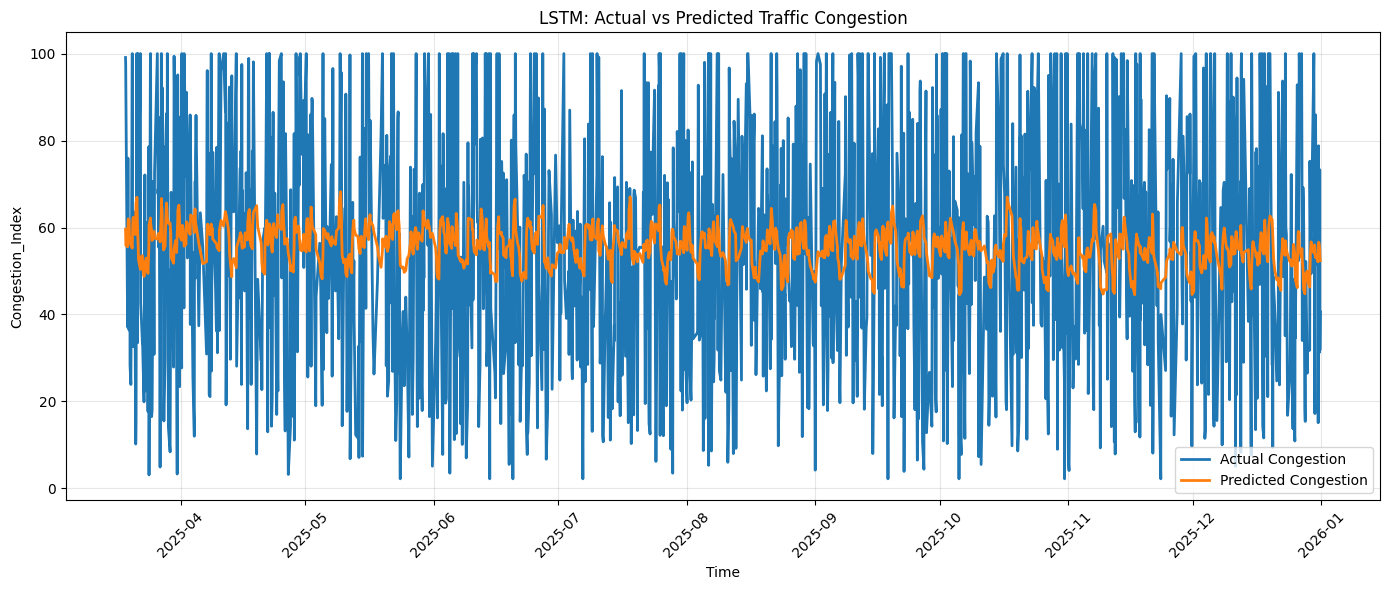

In [14]:
test_timestamps = hourly["timestamp"].iloc[
    split_index:split_index + len(y_actual)
].reset_index(drop=True)

plt.figure(figsize=(14, 6))

plt.plot(
    test_timestamps, y_actual,
    label="Actual Congestion", linewidth=2
)

plt.plot(
    test_timestamps, y_predicted,
    label="Predicted Congestion", linewidth=2
)

plt.title("LSTM: Actual vs Predicted Traffic Congestion")
plt.xlabel("Time")
plt.ylabel(TARGET_COL)
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

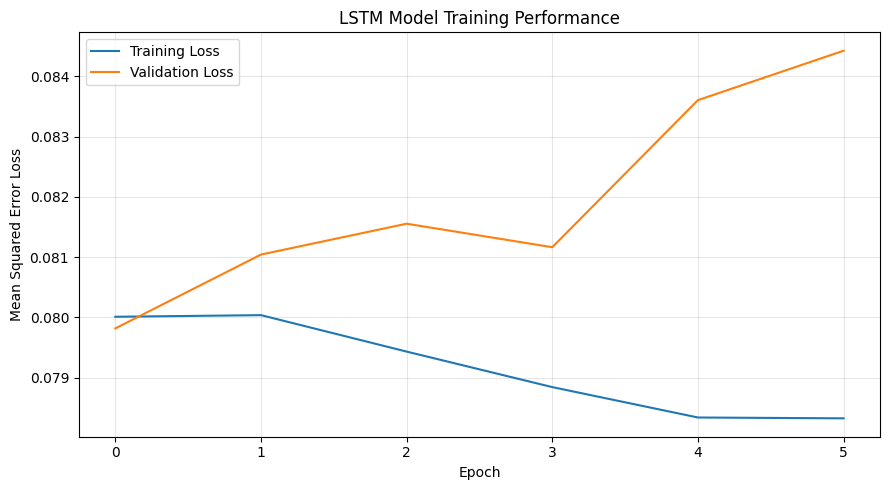

In [15]:
plt.figure(figsize=(9, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Model Training Performance")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
results = pd.DataFrame({
    "Timestamp": test_timestamps,
    "Actual_Congestion": y_actual,
    "Predicted_Congestion": y_predicted
})

results["Absolute_Error"] = abs(
    results["Actual_Congestion"] -
    results["Predicted_Congestion"]
)

display(results.head(20))

# Save predictions for your practical record.
results.to_csv(
    "/content/traffic_congestion_predictions.csv",
    index=False
)

print("Predictions saved successfully.")
files.download("/content/traffic_congestion_predictions.csv")

,Timestamp,Actual_Congestion,Predicted_Congestion,Absolute_Error
0,2025-03-18 16:00:00,99.099998,59.635448,39.464550
1,2025-03-18 17:00:00,97.599998,57.662975,39.937023
2,2025-03-18 18:00:00,91.099998,55.871792,35.228207
3,2025-03-19 04:00:00,37.099998,55.566368,18.466370
4,2025-03-19 06:00:00,75.949997,59.405651,16.544346
5,2025-03-19 07:00:00,58.699997,61.383808,2.683811
6,2025-03-19 08:00:00,37.200001,61.985424,24.785423
7,2025-03-19 13:00:00,36.400002,61.616512,25.216511
8,2025-03-19 14:00:00,54.599998,59.170414,4.570415
9,2025-03-19 15:00:00,42.599998,57.559349,14.959351


Predictions saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
results = pd.DataFrame({
    "Timestamp": test_timestamps,
    "Actual_Congestion": y_actual,
    "Predicted_Congestion": y_predicted
})

results["Absolute_Error"] = abs(
    results["Actual_Congestion"] -
    results["Predicted_Congestion"]
)

display(results.head(20))

# Save predictions for your practical record.
results.to_csv(
    "/content/traffic_congestion_predictions.csv",
    index=False
)

print("Predictions saved successfully.")
files.download("/content/traffic_congestion_predictions.csv")

,Timestamp,Actual_Congestion,Predicted_Congestion,Absolute_Error
0,2025-03-18 16:00:00,99.099998,59.635448,39.464550
1,2025-03-18 17:00:00,97.599998,57.662975,39.937023
2,2025-03-18 18:00:00,91.099998,55.871792,35.228207
3,2025-03-19 04:00:00,37.099998,55.566368,18.466370
4,2025-03-19 06:00:00,75.949997,59.405651,16.544346
5,2025-03-19 07:00:00,58.699997,61.383808,2.683811
6,2025-03-19 08:00:00,37.200001,61.985424,24.785423
7,2025-03-19 13:00:00,36.400002,61.616512,25.216511
8,2025-03-19 14:00:00,54.599998,59.170414,4.570415
9,2025-03-19 15:00:00,42.599998,57.559349,14.959351


Predictions saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 EMERGENCY DISPATCH - TRAFFIC CONGESTION FORECASTING
Deep Learning Model : LSTM
Lookback Period     : 24 hours
Test Records        : 1645
-------------------------------------------------------
Mean Absolute Error (MAE)  : 22.7352
Root Mean Squared Error    : 26.9115

RUNTIME PREDICTION OUTPUT


,Timestamp,Actual Congestion,Predicted Congestion,Absolute Error
0,2025-03-18 16:00:00,99.099998,59.634998,39.465000
1,2025-03-18 17:00:00,97.599998,57.662998,39.937000
2,2025-03-18 18:00:00,91.099998,55.872002,35.228001
3,2025-03-19 04:00:00,37.099998,55.566002,18.466000
4,2025-03-19 06:00:00,75.949997,59.405998,16.544001
5,2025-03-19 07:00:00,58.700001,61.383999,2.684000
6,2025-03-19 08:00:00,37.200001,61.985001,24.785000
7,2025-03-19 13:00:00,36.400002,61.617001,25.216999
8,2025-03-19 14:00:00,54.599998,59.169998,4.570000
9,2025-03-19 15:00:00,42.599998,57.558998,14.959000


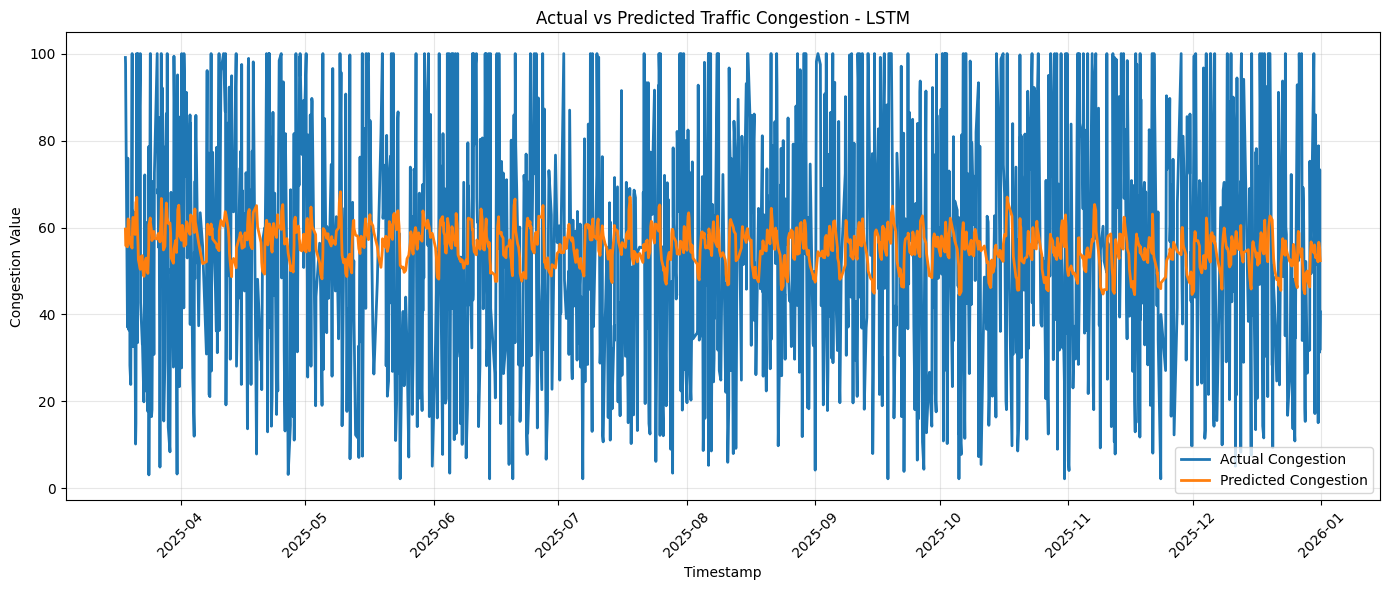


Runtime output saved successfully!


In [18]:
# RUNTIME OUTPUT - TRAFFIC CONGESTION FORECASTING

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Display model evaluation
mae = mean_absolute_error(y_actual, y_predicted)
rmse = np.sqrt(mean_squared_error(y_actual, y_predicted))

print("=" * 55)
print(" EMERGENCY DISPATCH - TRAFFIC CONGESTION FORECASTING")
print("=" * 55)
print("Deep Learning Model : LSTM")
print("Lookback Period     : 24 hours")
print("Test Records        :", len(y_actual))
print("-" * 55)
print(f"Mean Absolute Error (MAE)  : {mae:.4f}")
print(f"Root Mean Squared Error    : {rmse:.4f}")
print("=" * 55)

# 2. Display actual and predicted values
runtime_output = pd.DataFrame({
    "Timestamp": test_timestamps,
    "Actual Congestion": y_actual,
    "Predicted Congestion": y_predicted
})

runtime_output["Absolute Error"] = np.abs(
    runtime_output["Actual Congestion"] -
    runtime_output["Predicted Congestion"]
)

print("\nRUNTIME PREDICTION OUTPUT")
display(runtime_output.head(20).round(3))

# 3. Plot actual vs predicted congestion
plt.figure(figsize=(14, 6))
plt.plot(
    test_timestamps, y_actual,
    label="Actual Congestion", linewidth=2
)
plt.plot(
    test_timestamps, y_predicted,
    label="Predicted Congestion", linewidth=2
)

plt.title("Actual vs Predicted Traffic Congestion - LSTM")
plt.xlabel("Timestamp")
plt.ylabel("Congestion Value")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Save runtime output for GitHub
runtime_output.to_csv(
    "/content/runtime_prediction_output.csv",
    index=False
)

print("\nRuntime output saved successfully!")

 EMERGENCY DISPATCH - TRAFFIC CONGESTION FORECASTING
Deep Learning Model : LSTM
Lookback Period     : 24 hours
Test Records        : 1645
-------------------------------------------------------
Mean Absolute Error (MAE)  : 22.7352
Root Mean Squared Error    : 26.9115

RUNTIME PREDICTION OUTPUT


,Timestamp,Actual Congestion,Predicted Congestion,Absolute Error
0,2025-03-18 16:00:00,99.099998,59.634998,39.465000
1,2025-03-18 17:00:00,97.599998,57.662998,39.937000
2,2025-03-18 18:00:00,91.099998,55.872002,35.228001
3,2025-03-19 04:00:00,37.099998,55.566002,18.466000
4,2025-03-19 06:00:00,75.949997,59.405998,16.544001
5,2025-03-19 07:00:00,58.700001,61.383999,2.684000
6,2025-03-19 08:00:00,37.200001,61.985001,24.785000
7,2025-03-19 13:00:00,36.400002,61.617001,25.216999
8,2025-03-19 14:00:00,54.599998,59.169998,4.570000
9,2025-03-19 15:00:00,42.599998,57.558998,14.959000


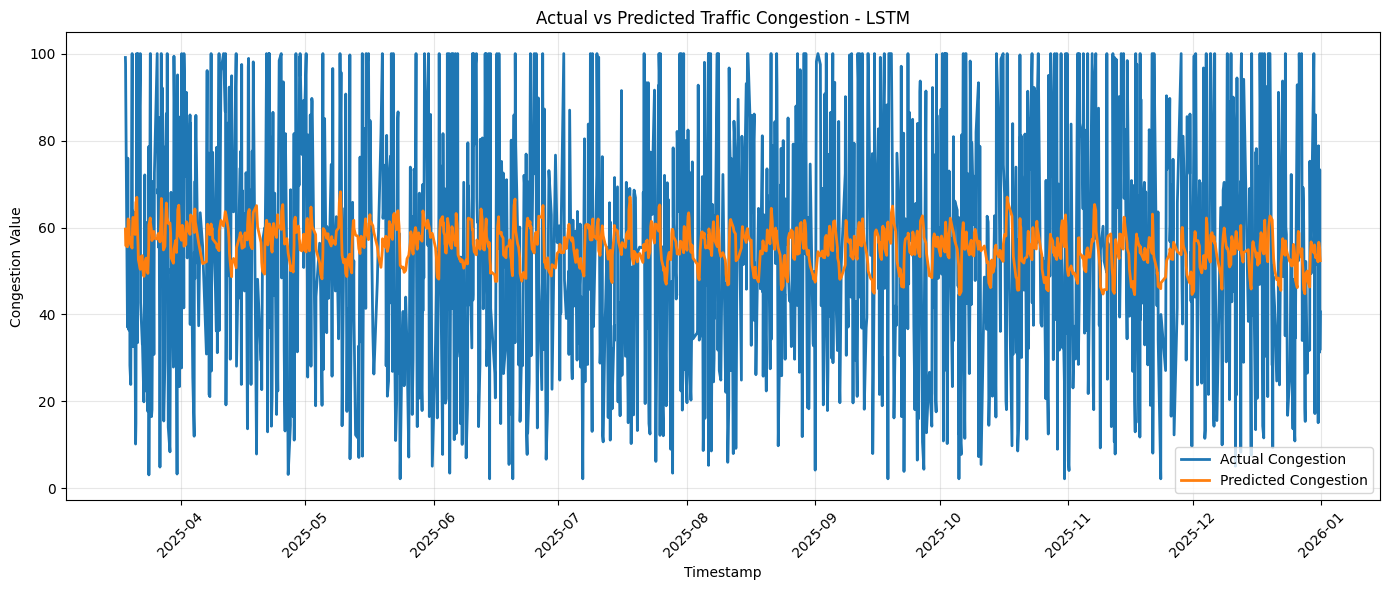


Runtime output saved successfully!


In [19]:
# RUNTIME OUTPUT - TRAFFIC CONGESTION FORECASTING

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Display model evaluation
mae = mean_absolute_error(y_actual, y_predicted)
rmse = np.sqrt(mean_squared_error(y_actual, y_predicted))

print("=" * 55)
print(" EMERGENCY DISPATCH - TRAFFIC CONGESTION FORECASTING")
print("=" * 55)
print("Deep Learning Model : LSTM")
print("Lookback Period     : 24 hours")
print("Test Records        :", len(y_actual))
print("-" * 55)
print(f"Mean Absolute Error (MAE)  : {mae:.4f}")
print(f"Root Mean Squared Error    : {rmse:.4f}")
print("=" * 55)

# 2. Display actual and predicted values
runtime_output = pd.DataFrame({
    "Timestamp": test_timestamps,
    "Actual Congestion": y_actual,
    "Predicted Congestion": y_predicted
})

runtime_output["Absolute Error"] = np.abs(
    runtime_output["Actual Congestion"] -
    runtime_output["Predicted Congestion"]
)

print("\nRUNTIME PREDICTION OUTPUT")
display(runtime_output.head(20).round(3))

# 3. Plot actual vs predicted congestion
plt.figure(figsize=(14, 6))
plt.plot(
    test_timestamps, y_actual,
    label="Actual Congestion", linewidth=2
)
plt.plot(
    test_timestamps, y_predicted,
    label="Predicted Congestion", linewidth=2
)

plt.title("Actual vs Predicted Traffic Congestion - LSTM")
plt.xlabel("Timestamp")
plt.ylabel("Congestion Value")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Save runtime output for GitHub
runtime_output.to_csv(
    "/content/runtime_prediction_output.csv",
    index=False
)

print("\nRuntime output saved successfully!")

EMERGENCY DISPATCH TRAFFIC FORECASTING
Model: LSTM
Test records: 1645
MAE: 22.7352
RMSE: 26.9115


,Timestamp,Actual_Congestion,Predicted_Congestion,Absolute_Error
0,2025-03-18 16:00:00,99.099998,59.634998,39.465000
1,2025-03-18 17:00:00,97.599998,57.662998,39.937000
2,2025-03-18 18:00:00,91.099998,55.872002,35.228001
3,2025-03-19 04:00:00,37.099998,55.566002,18.466000
4,2025-03-19 06:00:00,75.949997,59.405998,16.544001
5,2025-03-19 07:00:00,58.700001,61.383999,2.684000
6,2025-03-19 08:00:00,37.200001,61.985001,24.785000
7,2025-03-19 13:00:00,36.400002,61.617001,25.216999
8,2025-03-19 14:00:00,54.599998,59.169998,4.570000
9,2025-03-19 15:00:00,42.599998,57.558998,14.959000


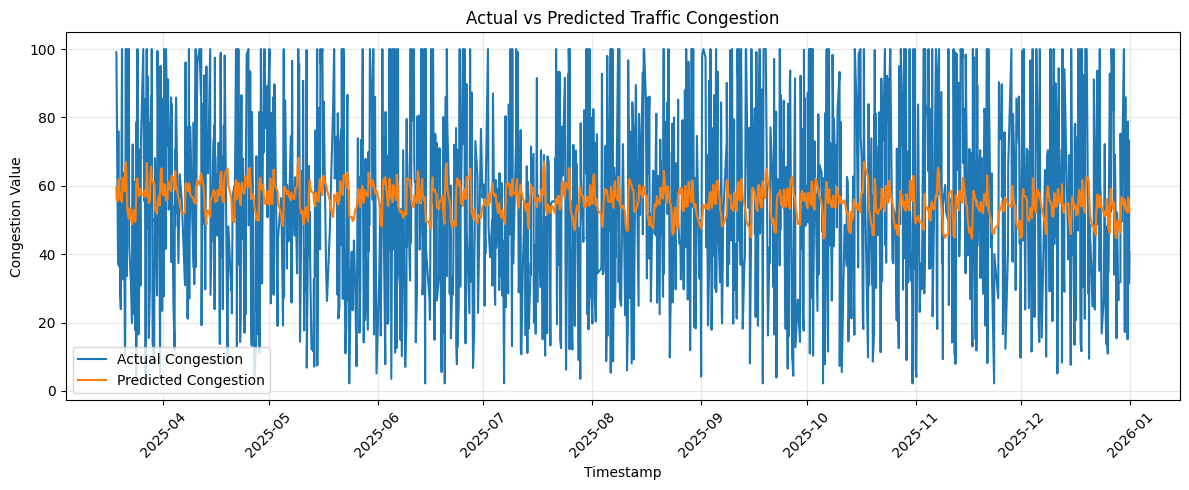


All runtime output files created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from google.colab import files
from IPython.display import display

# Create output folder
output_dir = "/content/runtime_outputs"
os.makedirs(output_dir, exist_ok=True)

# Calculate evaluation metrics
mae = mean_absolute_error(y_actual, y_predicted)
rmse = np.sqrt(mean_squared_error(y_actual, y_predicted))

# Display runtime output
print("=" * 55)
print("EMERGENCY DISPATCH TRAFFIC FORECASTING")
print("=" * 55)
print("Model: LSTM")
print("Test records:", len(y_actual))
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print("=" * 55)

# Create prediction table
runtime_output = pd.DataFrame({
    "Timestamp": test_timestamps,
    "Actual_Congestion": y_actual,
    "Predicted_Congestion": y_predicted
})

runtime_output["Absolute_Error"] = np.abs(
    runtime_output["Actual_Congestion"] -
    runtime_output["Predicted_Congestion"]
)

display(runtime_output.head(20).round(3))

# Save CSV output
csv_path = f"{output_dir}/runtime_prediction_output.csv"
runtime_output.to_csv(csv_path, index=False)

# Save graph
plt.figure(figsize=(12, 5))
plt.plot(test_timestamps, y_actual, label="Actual Congestion")
plt.plot(test_timestamps, y_predicted, label="Predicted Congestion")
plt.title("Actual vs Predicted Traffic Congestion")
plt.xlabel("Timestamp")
plt.ylabel("Congestion Value")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

graph_path = f"{output_dir}/runtime_graph.png"
plt.savefig(graph_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close()

# Save text report
report_path = f"{output_dir}/runtime_report.txt"

with open(report_path, "w") as f:
    f.write("EMERGENCY DISPATCH TRAFFIC FORECASTING\n")
    f.write("=" * 45 + "\n")
    f.write("Deep Learning Model: LSTM\n")
    f.write(f"Test Records: {len(y_actual)}\n")
    f.write(f"MAE: {mae:.4f}\n")
    f.write(f"RMSE: {rmse:.4f}\n\n")
    f.write("PREDICTION RESULTS\n")
    f.write(runtime_output.head(20).to_string(index=False))

print("\nAll runtime output files created successfully!")

# Download all files
for path in [csv_path, graph_path, report_path]:
    files.download(path)